# 1: Raccolta ed Esplorazione Dati

Obiettivo: scaricare una serie storica di prezzi pulita e verificata.

**Nota sulla scelta dell'asset:** uso **SPY** (ETF che replica l'S&P 500).

(1) ha oltre 30 anni di storico molto liquido

(2) riflette il mercato ampio invece di un singolo titolo

(3) l'adjusted close incorpora dividendi/split, quindi i regimi riflettono davvero il comportamento del mercato e non artefatti tecnici.

Se preferissi l'indice puro senza il tracking error dell'ETF potrei usare ^GSPC, ma perderei l'adjusted close per i dividendi, per un HMM su regimi di mercato SPY resta la scelta più solida.

## Installazione pacchetti
Installo yfinance, pandas e matplotlib.

In [53]:
# Installazione delle librerie necessarie (silenziosa con -q)
!pip install -q yfinance pandas matplotlib


## Import
Importo le librerie che useremo.

In [54]:
# Import librerie
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Formattazione dei numeri nei DataFrame stampati: 4 decimali, perché rendimenti
# e volatilità giornalieri sono dell'ordine di 0.001-0.01 e con 2 si leggerebbe 0.00
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## Download dei dati storici
Scarico circa 9 anni di storico giornaliero per SPY.

In [55]:
# Parametri di download
TICKER = "SPY"
END_DATE = pd.Timestamp("2026-09-23")  # la data finale è fissata per mantenere costante il periodo storico analizzato, favorendo la riproducibilità dei risultati
START_DATE = END_DATE - pd.DateOffset(years=9)  # circa 9 anni di storico

raw_data = yf.download(
    TICKER,
    start=START_DATE.strftime('%Y-%m-%d'),
    end=END_DATE.strftime('%Y-%m-%d'),
    auto_adjust=False,   # vogliamo la colonna "Adj Close" esplicita, separata da "Close"
    progress=False
)

print(f"Righe scaricate: {len(raw_data)}")
raw_data.head()


Righe scaricate: 2260


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2017-09-25,216.8867,248.9300,249.5500,248.0800,249.1500,57064400
2017-09-26,217.0174,249.0800,249.7000,248.8100,249.4200,54082000
2017-09-27,217.8626,250.0500,250.4900,248.8700,249.8800,81001400
2017-09-28,218.1240,250.3500,250.4400,249.6300,249.7300,44778800
2017-09-29,218.8907,251.2300,251.3200,250.1300,250.3400,85578000


## Isolare la colonna Adjusted Close
Teniamo solo il prezzo di chiusura aggiustato (dividendi/split inclusi) e scartiamo Open/High/Low/Volume.
Gestiamo anche il caso in cui yfinance restituisca colonne MultiIndex.

In [56]:
if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.get_level_values(0)

# Selezioniamo solo l'adjusted close e lo rinominiamo
prices = raw_data[['Adj Close']].copy()
prices.rename(columns={'Adj Close': 'adj_close'}, inplace=True)
prices.index.name = 'date'

prices.head()


Price,adj_close
date,
2017-09-25,216.8867
2017-09-26,217.0174
2017-09-27,217.8626
2017-09-28,218.1240
2017-09-29,218.8907


## Controllo e gestione di valori mancanti / buchi
yfinance scarica solo i giorni in cui la borsa era aperta: weekend e festività USA non compaiono come NaN, semplicemente non ci sono righe per quei giorni.

Controlliamo comunque:

(1) NaN dentro la serie scaricata

(2) quanti giorni lavorativi (lun-ven) mancano rispetto a un calendario continuo, solo a scopo informativo (le festività di borsa ci rientrano, è atteso).

In [57]:
# 1) NaN nella serie scaricata
n_nan_before = int(prices['adj_close'].isna().sum())
print(f"Valori NaN trovati nella serie scaricata: {n_nan_before}")

# 2) Giorni lavorativi (Mon-Fri) assenti rispetto a un calendario continuo
full_bdays = pd.date_range(start=prices.index.min(), end=prices.index.max(), freq='B')
missing_bdays = full_bdays.difference(prices.index)
print(f"Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): {len(missing_bdays)}")

# Gestione dei NaN, se presenti:
# - forward-fill: un prezzo mancante viene sostituito con l'ultimo prezzo valido precedente
#   ("nessun trading = prezzo invariato")
# - backward-fill di sicurezza SOLO per eventuali NaN residui a inizio serie
#   (dove non esiste un valore precedente da propagare in avanti)
if n_nan_before > 0:
    prices['adj_close'] = prices['adj_close'].ffill().bfill()
    n_nan_after = int(prices['adj_close'].isna().sum())
    print(f"NaN dopo forward-fill (+ backward-fill di sicurezza): {n_nan_after}")
else:
    n_nan_after = 0
    print("Nessun NaN da gestire: la serie scaricata e' gia' completa.")


Valori NaN trovati nella serie scaricata: 0
Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): 87
Nessun NaN da gestire: la serie scaricata e' gia' completa.


## Plot del prezzo nel tempo
Grafico semplice per un controllo visivo: vogliamo vedere se la serie è "continua", senza salti anomali.

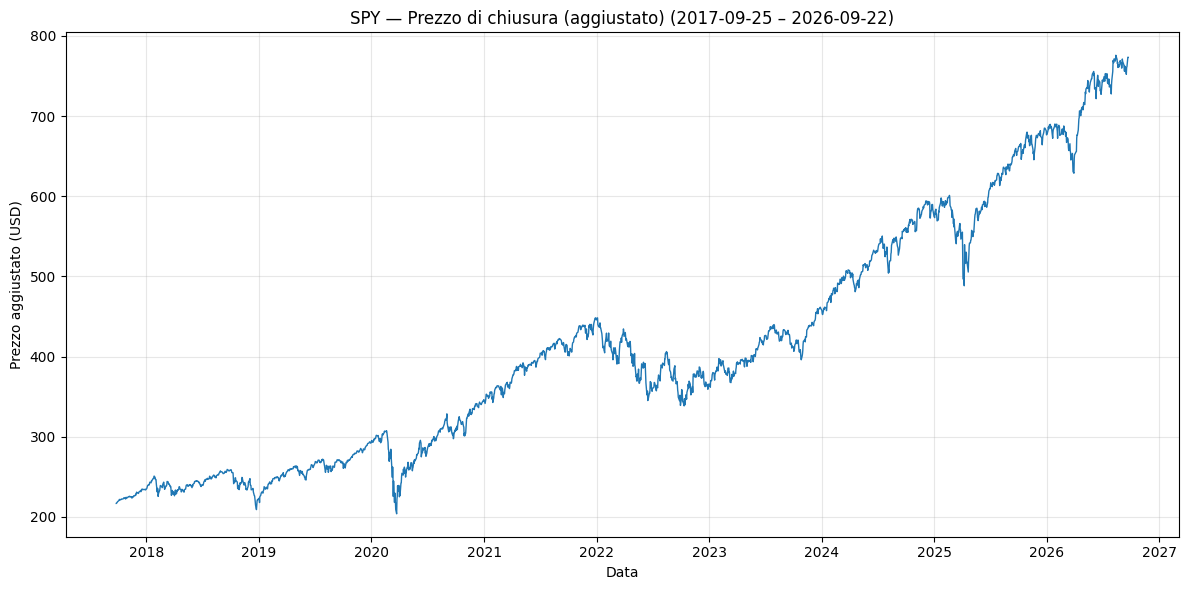

In [58]:
plt.figure(figsize=(12, 6))
plt.plot(prices.index, prices['adj_close'], linewidth=1)
plt.title(f"{TICKER} — Prezzo di chiusura (aggiustato) "
          f"({prices.index.min().date()} – {prices.index.max().date()})")
plt.xlabel("Data")
plt.ylabel("Prezzo aggiustato (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Riepilogo finale
Riepilogo: quante righe abbiamo, il range di date coperto, e cosa è successo con eventuali valori mancanti.

In [59]:
print("=" * 90)
print("SUMMARY: Dati", TICKER)
print("=" * 90)
print(f"Numero di righe (giorni di trading): {len(prices)}")
print(f"Range di date: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"NaN trovati nella serie originale: {n_nan_before}")
print(f"NaN dopo pulizia (ffill/bfill): {n_nan_after}")
print(f"Giorni lavorativi mancanti vs calendario continuo: {len(missing_bdays)} "
      f"(festivita' di borsa, atteso)")
print("-" * 90)


SUMMARY: Dati SPY
Numero di righe (giorni di trading): 2260
Range di date: 2017-09-25 -> 2026-09-22
NaN trovati nella serie originale: 0
NaN dopo pulizia (ffill/bfill): 0
Giorni lavorativi mancanti vs calendario continuo: 87 (festivita' di borsa, atteso)
------------------------------------------------------------------------------------------


# 2: Feature Engineering
Calcoliamo log return giornalieri e volatilità
rolling a 20 giorni, le feature che useremo per l'HMM.


In [60]:
import numpy as np


### Log return giornalieri
Perché log returns:

(1) additivi nel tempo (la somma di log return = log return cumulato)

(2) proprietà statistiche più stabili nel tempo rispetto al prezzo


In [61]:
# log_return_t = log(P_t) - log(P_t-1) = log(P_t / P_t-1)
prices['log_return'] = np.log(prices['adj_close'] / prices['adj_close'].shift(1))

prices[['adj_close', 'log_return']].head()


Price,adj_close,log_return
date,,
2017-09-25,216.8867,NaN
2017-09-26,217.0174,0.0006
2017-09-27,217.8626,0.0039
2017-09-28,218.1240,0.0012
2017-09-29,218.8907,0.0035


### Volatilità rolling (finestra 20 giorni)
Deviazione standard rolling dei log return su 20 giorni di trading (1 mese).


In [62]:
ROLLING_WINDOW = 20  # giorni di trading

prices['volatility_20d'] = prices['log_return'].rolling(window=ROLLING_WINDOW).std()

prices[['log_return', 'volatility_20d']].tail()


Price,log_return,volatility_20d
date,,
2026-09-16,-0.0044,0.0054
2026-09-17,0.0113,0.0061
2026-09-18,0.0013,0.0058
2026-09-21,0.0154,0.0067
2026-09-22,-0.0002,0.0066


### NaN introdotti dal calcolo rolling
1 NaN in log_return (primo giorno) e 20 in volatility_20d (finestra incompleta):
strutturali e attesi, li rimuoviamo con dropna mirato invece di riempirli.


In [63]:
n_nan_return = int(prices['log_return'].isna().sum())
n_nan_vol = int(prices['volatility_20d'].isna().sum())

print(f"NaN in log_return:     {n_nan_return}  (atteso: 1)")
print(f"NaN in volatility_20d: {n_nan_vol}  (atteso: {ROLLING_WINDOW })")

features = prices.dropna(subset=['log_return', 'volatility_20d']).copy()

print(f"\nRighe prima della pulizia: {len(prices)}")
print(f"Righe dopo la pulizia:    {len(features)}")
print(f"NaN residui in features:  {int(features[['log_return', 'volatility_20d']].isna().sum().sum())}")


NaN in log_return:     1  (atteso: 1)
NaN in volatility_20d: 20  (atteso: 20)

Righe prima della pulizia: 2260
Righe dopo la pulizia:    2240
NaN residui in features:  0


### Plot: prezzo, rendimenti e volatilità allineati nel tempo


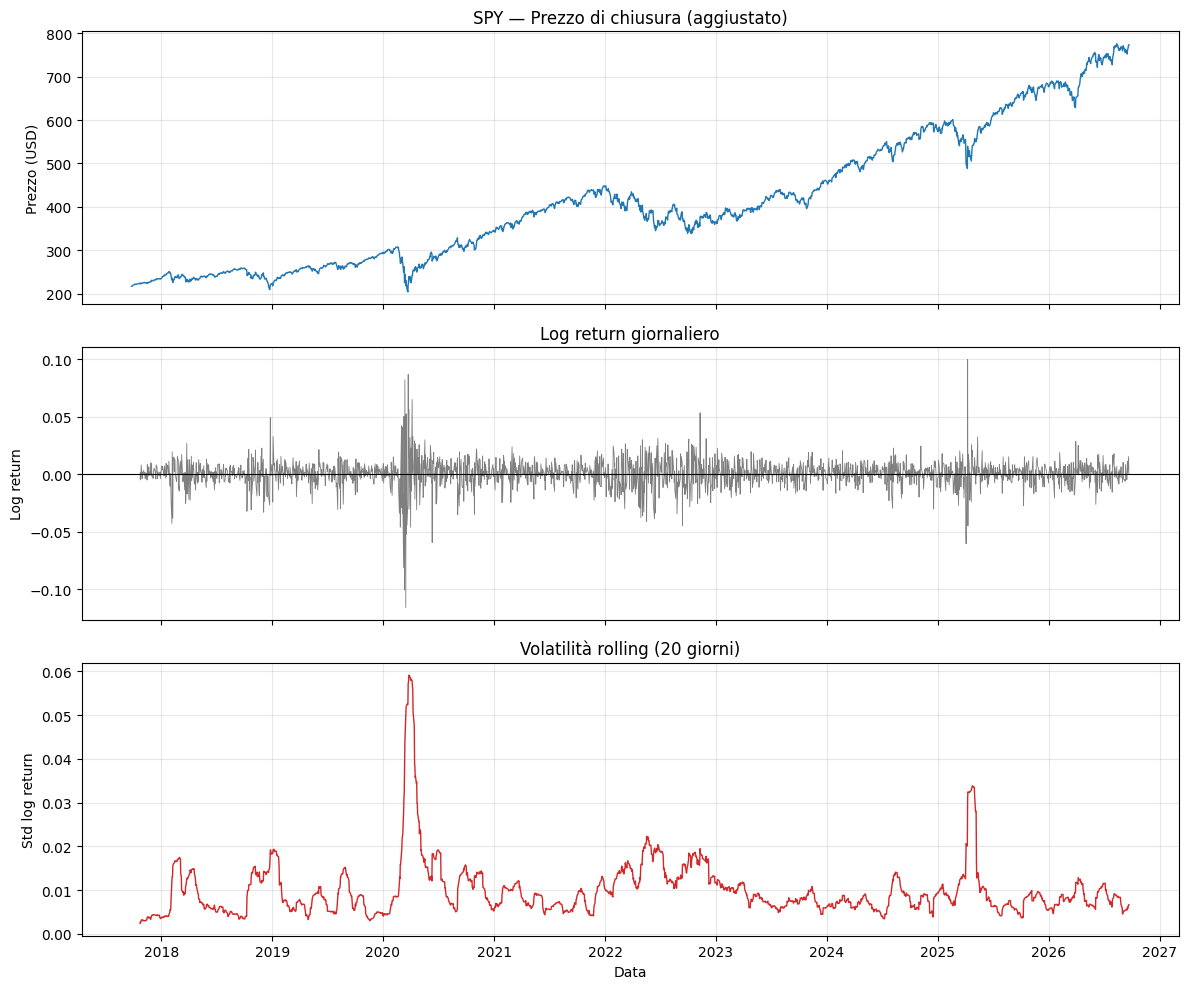

In [64]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(prices.index, prices['adj_close'], linewidth=1, color='tab:blue')
axes[0].set_title(f"{TICKER} — Prezzo di chiusura (aggiustato)")
axes[0].set_ylabel("Prezzo (USD)")
axes[0].grid(alpha=0.3)

axes[1].plot(features.index, features['log_return'], linewidth=0.6, color='tab:gray')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title("Log return giornaliero")
axes[1].set_ylabel("Log return")
axes[1].grid(alpha=0.3)

axes[2].plot(features.index, features['volatility_20d'], linewidth=1, color='tab:red')
axes[2].set_title(f"Volatilità rolling ({ROLLING_WINDOW} giorni)")
axes[2].set_ylabel("Std log return")
axes[2].set_xlabel("Data")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Riepilogo statistico finale


In [65]:
print("=" * 40)
print("SUMMARY: Feature Engineering")
print("=" * 40)
print(f"Righe finali (dopo pulizia NaN): {len(features)}")
print(f"Range di date: {features.index.min().date()} -> {features.index.max().date()}")
print("-" * 40)
print("Log return giornaliero:")
print(features['log_return'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)
print(f"Volatilità rolling ({ROLLING_WINDOW}gg):")
print(features['volatility_20d'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)


SUMMARY: Feature Engineering
Righe finali (dopo pulizia NaN): 2240
Range di date: 2017-10-23 -> 2026-09-22
----------------------------------------
Log return giornaliero:
mean    0.0006
std     0.0119
min    -0.1159
max     0.0999
Name: log_return, dtype: float64
----------------------------------------
Volatilità rolling (20gg):
mean   0.0100
std    0.0066
min    0.0024
max    0.0592
Name: volatility_20d, dtype: float64
----------------------------------------
